# Демо 1. Ембединги й семантичний пошук

У цьому ноутбуці перетворюємо тексти на **ембединги**. Ембединги — це вектори, у які перетворюються тексти таким чином, що близькі за значенням тексти мають вектори близькі за розміщенням у векторному просторі. На базі цієї властивості будуємо семантичний пошук. З метою навчання робимо це без жодних спеціалізованих бібліотек,
використовуємо лише `numpy`.

Документи для пошуку — нормативні документи Житомирської політехніки з [docs.ztu.edu.ua](https://docs.ztu.edu.ua/):
положення про оцінювання, гуртожитки, стипендії, старосту академічної групи тощо.
Мовна модель, яка потім буде використовуватися для генерації, швидше за все не бачила цих документів під час тренування, тому відповісти на питання про них
вона зможе лише тоді, коли потрібний фрагмент документа буде знайдено й передано їй у промпті.
Пошук потрібних фрагментів документа і є першою половиною RAG.

_Зверніть увагу: ноутбук працює і на CPU, але з GPU ембединги рахуються швидше._

### Службова клітинка: таймер виконання

Ця клітинка потрібна для відповіді на питання про тривалість виконання: вона підключає до IPython обробник, який після кожної клітинки записує, скільки секунд вона виконувалася. Запускайте її **першою**.

In [1]:
# Службова клітинка до питання про тривалість: запамʼятовує, скільки секунд виконувалася кожна клітинка.
# Запускайте її першою, до всіх інших клітинок ноутбука.
import json
import os
import time

from IPython import get_ipython

TIMES_FILE = "cell_times_01.json"  # файл переживе перезапуск середовища в межах сесії Colab
CELL_TIMES = json.load(open(TIMES_FILE)) if os.path.exists(TIMES_FILE) else []
_started = [None]


def _pre_run(*args):
    _started[0] = time.perf_counter()


def _post_run(result=None):
    if _started[0] is None:  # саму службову клітинку не вимірюємо
        return
    raw = (getattr(getattr(result, "info", None), "raw_cell", "") or "").strip()
    CELL_TIMES.append({
        "cell": getattr(result, "execution_count", None),
        "sec": round(time.perf_counter() - _started[0], 1),
        "code": raw.splitlines()[0][:70] if raw else "",
    })
    with open(TIMES_FILE, "w") as f:
        json.dump(CELL_TIMES, f)


ip = get_ipython()
for event, callback in (("pre_run_cell", _pre_run), ("post_run_cell", _post_run)):
    for old in list(ip.events.callbacks[event]):
        if getattr(old, "__name__", "") == callback.__name__:
            ip.events.unregister(event, old)
    ip.events.register(event, callback)
print("Таймер клітинок увімкнено")

Таймер клітинок увімкнено


In [2]:
# sentence-transformers — бібліотека для обчислення ембедингів текстів, pypdf — витягування тексту з PDF
!pip install -q "sentence-transformers>=5" pypdf

In [3]:
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")

Пристрій: cuda


## 1. Модель ембедингів

Для перетворення текстових фрагментів на ембединги використовують спеціальні ембедингові моделі. [Qwen3-Embedding-0.6B](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) — багатомовна модель ембедингів із сімʼї моделей Qwen3. Вона перетворює текст довжиною до ~32 тис. токенів на вектор
із 1024 чисел. Ці два числа: максимальний розмір вхідного тексту і розмірність результуючого ембедингу - є важливими характеристиками ембедингових моделей.

In [4]:
EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
dtype = torch.float16 if device == "cuda" else torch.float32
model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=device, model_kwargs={"dtype": dtype})

print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")
print(f"Максимальна довжина тексту в токенах: {model.max_seq_length}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Розмірність ембедингу: 1024
Максимальна довжина тексту в токенах: 32768


/tmp/ipykernel_350/1793327947.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Розмірність ембедингу: {model.get_sentence_embedding_dimension()}")


## 2. Ембединг одного речення

Незалежно від довжини тексту модель повертає вектор однакової розмірності.
Параметр `normalize_embeddings=True` ділить вектор на його евклідову ($L_{2}$) норму. Формула евклідової норми:

$$
\|\vec{x}\|_{2} = \sqrt{\sum_{i=1}^{n}x_{i}^{2}}
$$


Таким чином довжина (норма) вектора дорівнює 1.
Так косинусна подібність, яку потім потрібно часто підраховувати, зводиться до скалярного добутку.

In [5]:
sentence = "Чому я такий розумний?"
embedding = model.encode(sentence, normalize_embeddings=True)

print(f"Форма: {embedding.shape}")
print(f"Перші 8 чисел: {embedding[:8]}")
print(f"Евклідова норма вектора: {np.linalg.norm(embedding):.4f}")

# Загалом модель сама нормалізує вектор всередині,
# тому `normalize_embeddings=True` є зайвим у цьому конкретному випадку
# зверніть увагу на останній шар моделі
print(model)

Форма: (1024,)
Перші 8 чисел: [-0.02551   -0.09235   -0.0002925  0.02061    0.007275   0.0573
 -0.0488     0.04395  ]
Евклідова норма вектора: 1.0000
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'Qwen3Model'})
  (1): Pooling({'embedding_dimension': 1024, 'pooling_mode': 'lasttoken', 'include_prompt': True})
  (2): Normalize({})
)


## 3. Косинусна подібність

Близькість двох ембедингів вимірюють **косинусом кута** між ними:

$$\cos(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Значення `1` означає однаковий напрям векторів, `0` — ортогональні вектори, `-1` - вектори вказують у повністю протилежні сторони.
Для нормалізованих векторів знаменник дорівнює 1, і косинус дорівнює скалярному добутку.
Порахуємо його вручну й порівняємо з вбудованим методом `model.similarity`.

In [6]:
a, b, c = model.encode(
    ["Скільки коштує проживання в гуртожитку?",
     "Яка плата за місце в студентському гуртожитку?",
     "Чому Політехніка краще за Гарвард?"],
    normalize_embeddings=True,
)

manual = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
with_library = model.similarity(a, b).item()

print(f"Вручну (a <=> b):     {manual:.4f}")
print(f"Бібліотека (a <=> b): {with_library:.4f}")

print(f"Бібліотека (a <=> c): {model.similarity(a, c).item():.4f}")

Вручну (a <=> b):     0.6489
Бібліотека (a <=> b): 0.6489
Бібліотека (a <=> c): 0.2329


In [7]:
# Оскільки, як зазначалося вище, ембединги є зазвичай нормалізованими векторами, то знаменник дорівнює `1`.
# Перевіримо це:
print(f"Норма a: {np.linalg.norm(a):.4f}")
print(f"Норма b: {np.linalg.norm(b):.4f}")
print(f"Норма c: {np.linalg.norm(c):.4f}")

Норма a: 1.0000
Норма b: 1.0000
Норма c: 1.0000


In [8]:
# Зважаючи на це ми можемо опускати нижню частину формули косинусної подібності
# і вираховувати її лише як скалярний добуток двох векторів

pure_dot_product = np.dot(a, b)
vector_norm_product = np.linalg.norm(a) * np.linalg.norm(b)

assert round(pure_dot_product, 4) == round(manual, 4) == round(with_library, 4), "The teacher made a mistake!"
assert np.isclose(vector_norm_product, 1), "The teacher doesn't know math"

### Косинусна подібність на простих векторах

Ембединг має 1024 виміри, але формула однакова для будь-якої розмірності.
Розглянемо її на двовимірних векторах, які можна намалювати. Вектор $a = (3, 1)$ порівнюємо з чотирма іншими:
- $e = (6, 2)$ — той самий напрям, але вдвічі довший;
- $b = (2, 2)$ — близький напрям;
- $c = (-1, 3)$ — перпендикулярний напрям;
- $d = (-3, -1)$ — протилежний напрям.

a·e =   20   ‖a‖·‖e‖ = 20.00   cos =  1.00   кут =   0.0°
a·b =    8   ‖a‖·‖b‖ =  8.94   cos =  0.89   кут =  26.6°
a·c =    0   ‖a‖·‖c‖ = 10.00   cos =  0.00   кут =  90.0°
a·d =  -10   ‖a‖·‖d‖ = 10.00   cos = -1.00   кут = 180.0°


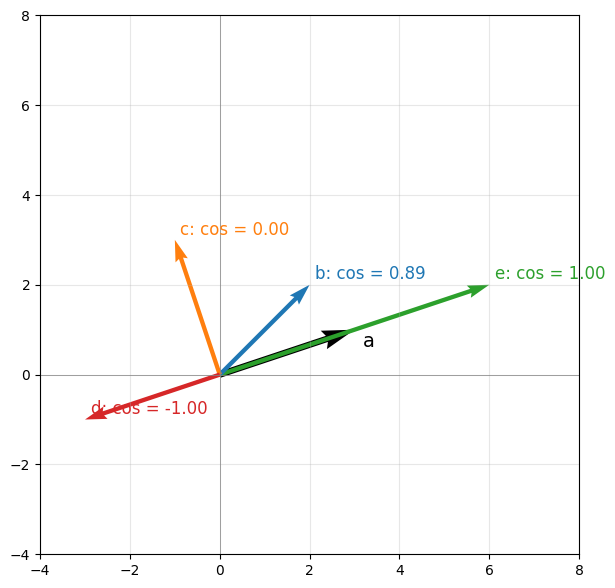

In [9]:
a2 = np.array([3, 1])
others = {
    "e": np.array([6, 2]),
    "b": np.array([2, 2]),
    "c": np.array([-1, 3]),
    "d": np.array([-3, -1]),
}


def cosine(u, v):
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))


for name, v in others.items():
    dot = np.dot(a2, v)
    norms = np.linalg.norm(a2) * np.linalg.norm(v)
    angle = np.degrees(np.arccos(np.clip(cosine(a2, v), -1, 1)))
    print(f"a·{name} = {dot:4}   ‖a‖·‖{name}‖ = {norms:5.2f}   cos = {dot / norms:5.2f}   кут = {angle:5.1f}°")

fig, ax = plt.subplots(figsize=(7, 7))
ax.quiver(0, 0, *a2, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(f"{name}: cos = {cosine(a2, v):.2f}", v, xytext=(4, 4), textcoords="offset points",
                fontsize=12, color=color)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-4, 8)
ax.set_ylim(-4, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Косинус залежить лише від кута між векторами, а не від їхньої довжини: вектор $e$ удвічі довший за $a$,
але косинус дорівнює 1. Знаменник формули саме й прибирає вплив довжини.

Тепер нормалізуємо всі вектори — поділимо кожен на його довжину. Кінці нормалізованих векторів лежать
на колі радіуса 1, напрями не змінюються, а скалярний добуток дорівнює косинусу без жодного ділення.

e = [0.949 0.316]   довжина = 1.00   скалярний добуток =  1.00   cos =  1.00
b = [0.707 0.707]   довжина = 1.00   скалярний добуток =  0.89   cos =  0.89
c = [-0.316  0.949]   довжина = 1.00   скалярний добуток =  0.00   cos =  0.00
d = [-0.949 -0.316]   довжина = 1.00   скалярний добуток = -1.00   cos = -1.00


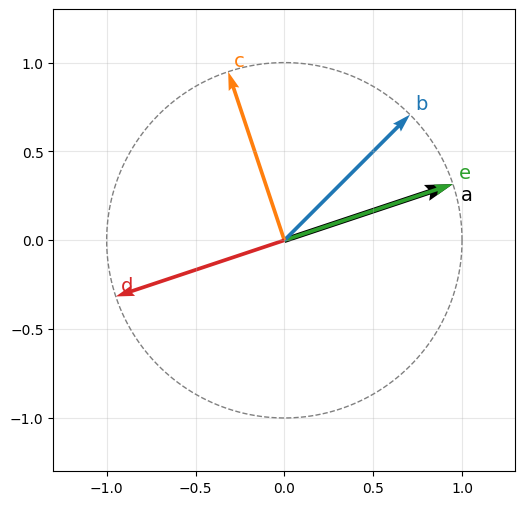

In [10]:
def normalize(v):
    return v / np.linalg.norm(v)


a2_unit = normalize(a2)
for name, v in others.items():
    v_unit = normalize(v)
    print(f"{name} = {np.round(v_unit, 3)}   довжина = {np.linalg.norm(v_unit):.2f}   "
          f"скалярний добуток = {np.dot(a2_unit, v_unit):5.2f}   cos = {cosine(a2, v):5.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(circle), np.sin(circle), color="grey", lw=1, ls="--")
ax.quiver(0, 0, *a2_unit, angles="xy", scale_units="xy", scale=1, color="black", width=0.012)
ax.annotate("a", a2_unit, xytext=(6, -12), textcoords="offset points", fontsize=14)
for (name, v), color in zip(others.items(), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    v_unit = normalize(v)
    ax.quiver(0, 0, *v_unit, angles="xy", scale_units="xy", scale=1, color=color, width=0.008)
    ax.annotate(name, v_unit, xytext=(4, 4), textcoords="offset points", fontsize=14, color=color)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

Вектори $a$ і $e$ після нормалізації збіглися: однаковий напрям — однаковий нормалізований вектор.

### Три виміри

У трьох вимірах усе так само: кожна компонента вектора — окрема вісь, скалярний добуток — сума
трьох попарних добутків. Нехай компоненти означають, наскільки текст стосується трьох тем:
гуртожитку, стипендії й погоди.

«плата за гуртожиток» і «заселення в гуртожиток»: a·b = 0.9·0.8 + 0.3·0.1 + 0.0·0.1 = 0.75, cos = 0.97
«плата за гуртожиток» і «стипендія»: a·b = 0.9·0.2 + 0.3·0.9 + 0.0·0.0 = 0.45, cos = 0.51
«плата за гуртожиток» і «погода»: a·b = 0.9·0.0 + 0.3·0.1 + 0.0·0.9 = 0.03, cos = 0.03


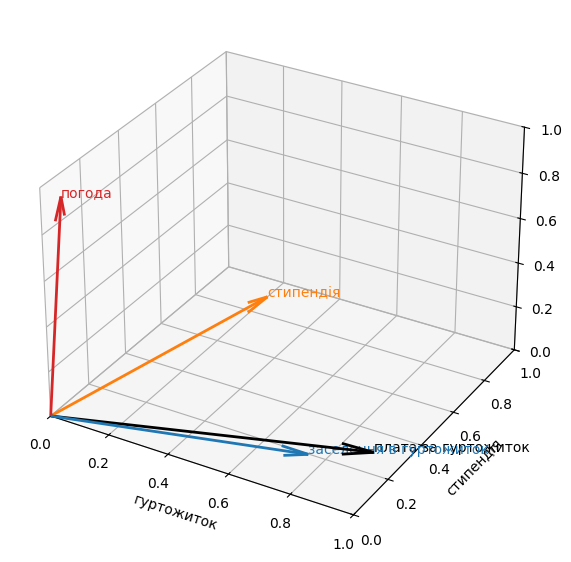

In [11]:
vectors_3d = {
    "плата за гуртожиток": np.array([0.9, 0.3, 0.0]),
    "заселення в гуртожиток": np.array([0.8, 0.1, 0.1]),
    "стипендія": np.array([0.2, 0.9, 0.0]),
    "погода": np.array([0.0, 0.1, 0.9]),
}
names_3d = list(vectors_3d)
query_3d = vectors_3d[names_3d[0]]
for name in names_3d[1:]:
    v = vectors_3d[name]
    products = " + ".join(f"{x:.1f}·{y:.1f}" for x, y in zip(query_3d, v))
    print(f"«{names_3d[0]}» і «{name}»: a·b = {products} = {np.dot(query_3d, v):.2f}, cos = {cosine(query_3d, v):.2f}")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
for (name, v), color in zip(vectors_3d.items(), ["black", "tab:blue", "tab:orange", "tab:red"]):
    ax.quiver(0, 0, 0, *v, color=color, arrow_length_ratio=0.1, linewidth=2)
    ax.text(*v, name, color=color, fontsize=10)
ax.set_xlabel("гуртожиток")
ax.set_ylabel("стипендія")
ax.set_zlabel("погода")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)
plt.show()

Справжній ембединг влаштований так само, лише замість трьох осей — 1024. На відміну від цього прикладу,
окремі виміри ембединга не мають зрозумілого людині змісту: значення має лише напрям вектора в цілому.

## 4. Матриця подібності

Порахуємо подібність кожного речення з кожним. Серед речень є:
- дві пари перефразувань (про плату за гуртожиток і про стипендію);
- два речення зі спільним словом «ключ», але різним змістом;
- речення, не повʼязане з рештою.

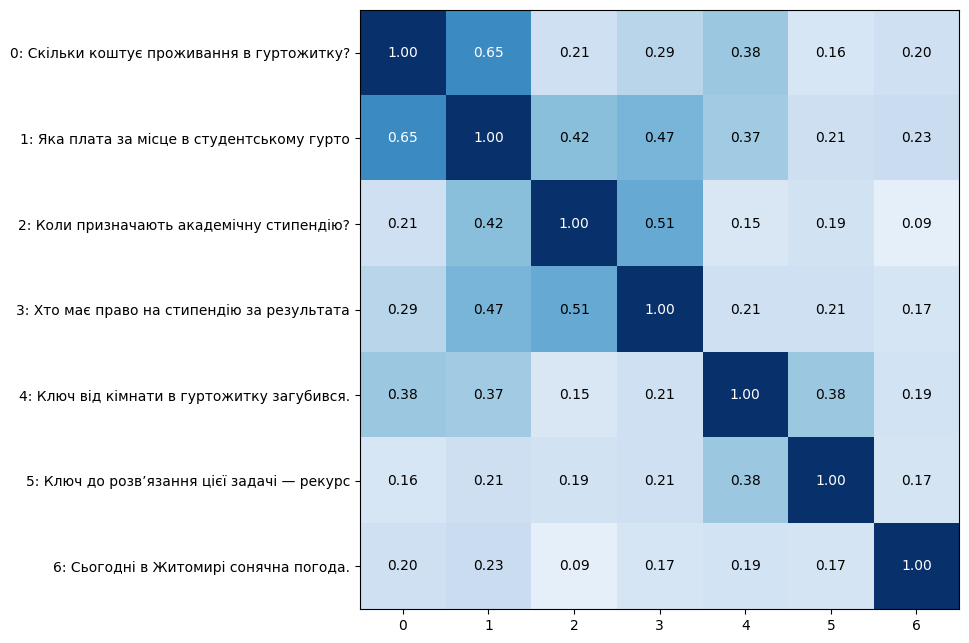

In [12]:
def show_similarity_matrix(sentences, figsize=(9, 7)):
  embeddings = model.encode(sentences, normalize_embeddings=True)
  similarity = embeddings @ embeddings.T

  fig, ax = plt.subplots(figsize=figsize)
  ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
  ax.set_xticks(range(len(sentences)), [f"{i}" for i in range(len(sentences))])
  ax.set_yticks(range(len(sentences)), [f"{i}: {s[:40]}" for i, s in enumerate(sentences)])
  for i in range(len(sentences)):
      for j in range(len(sentences)):
          ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                  color="white" if similarity[i, j] > 0.6 else "black")
  plt.tight_layout()
  plt.show()

uni_sentences = [
    "Скільки коштує проживання в гуртожитку?",
    "Яка плата за місце в студентському гуртожитку?",
    "Коли призначають академічну стипендію?",
    "Хто має право на стипендію за результатами сесії?",
    "Ключ від кімнати в гуртожитку загубився.",
    "Ключ до розвʼязання цієї задачі — рекурсія.",
    "Сьогодні в Житомирі сонячна погода.",
]

show_similarity_matrix(uni_sentences)


Перефразування мають найвищу подібність, хоча містять лише одне спільне слово, так само як і пара з речень 4-5, схожість яких вдвічі менша.
Водночас подібність ніколи не падає до нуля: навіть речення про погоду має з рештою додатну подібність.

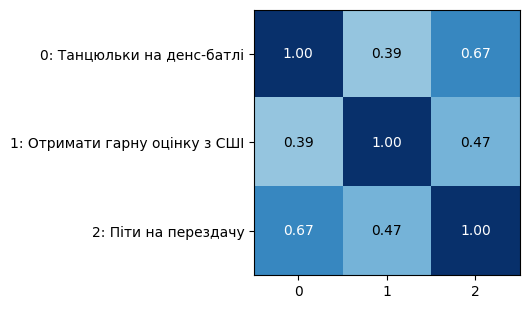

In [13]:
# Пограємося, вимірюючи подібність цілком випадкових і взагалі не придуманих викладачем фраз

pseudo_random_sentences = [
    "Танцюльки на денс-батлі",
    "Отримати гарну оцінку з СШІ",
    "Піти на перездачу"
]

show_similarity_matrix(pseudo_random_sentences, figsize=(5, 4))


## 5. Тексти на площині

Вектор із 1024 чисел неможливо намалювати, тому проєктуємо ембединги на площину методом головних компонент (Principal Component Analysis, PCA).
Проєкція втрачає більшу частину інформації, але групи речень на одну тему видно й на ній.

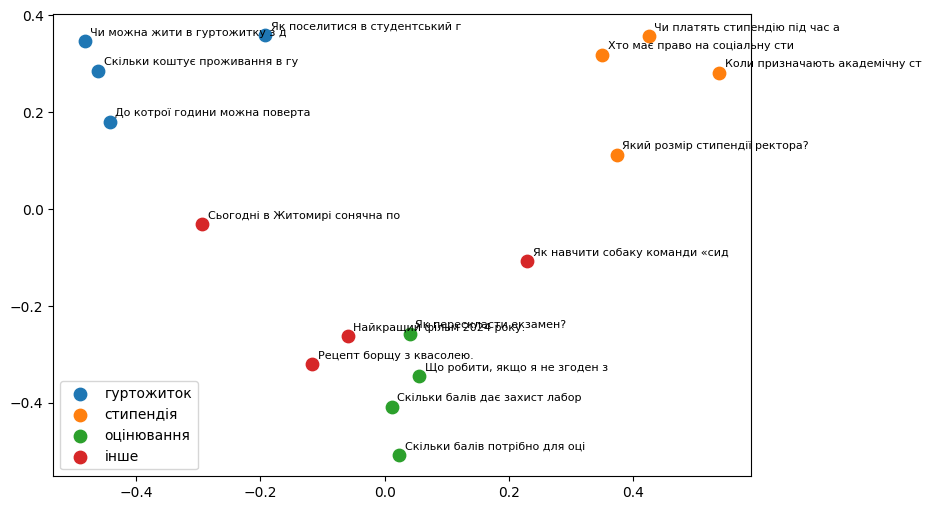

In [14]:
topics = {
    "гуртожиток": [
        "Скільки коштує проживання в гуртожитку?",
        "Як поселитися в студентський гуртожиток?",
        "До котрої години можна повертатися в гуртожиток?",
        "Чи можна жити в гуртожитку з дружиною?",
    ],
    "стипендія": [
        "Коли призначають академічну стипендію?",
        "Хто має право на соціальну стипендію?",
        "Який розмір стипендії ректора?",
        "Чи платять стипендію під час академічної відпустки?",
    ],
    "оцінювання": [
        "Скільки балів потрібно для оцінки «відмінно»?",
        "Що робити, якщо я не згоден з оцінкою?",
        "Як перескласти екзамен?",
        "Скільки балів дає захист лабораторної роботи?",
    ],
    "інше": [
        "Сьогодні в Житомирі сонячна погода.",
        "Рецепт борщу з квасолею.",
        "Найкращий фільм 2024 року.",
        "Як навчити собаку команди «сидіти»?",
    ],
}
texts = [t for group in topics.values() for t in group]
labels = [name for name, group in topics.items() for _ in group]
# На GPU модель працює у float16, а SVD у numpy підтримує лише float32 і float64
points = model.encode(texts, normalize_embeddings=True).astype(np.float32)

centered = points - points.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(9, 6))
for name in topics:
    mask = np.array(labels) == name
    ax.scatter(xy[mask, 0], xy[mask, 1], s=80, label=name)
for (x, y), t in zip(xy, texts):
    ax.annotate(t[:30], (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend()
plt.show()

## 6. Запит і документ кодуються по-різному

Короткий запит («до якої дати платити?») і фрагмент документа, що містить відповідь, — тексти різного вигляду.
Тому багато моделей ембедингів додають до запиту інструкцію. Qwen3-Embedding зберігає її у промпті `query`,
а документи кодує без інструкції.

In [15]:
print(repr(model.prompts["query"]))
print(repr(model.prompts["document"]))

'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'
''


In [16]:
passages = [
    "Студент вносить авансовий платіж за 1 семестр до 1 вересня, а за 2 семестр – до 1 лютого.",
    "З 23:00 години і до 7:00 години в гуртожитку повинна додержуватись тиша.",
    "Вибори старости академічної групи на 1 курсі відбуваються після двох тижнів навчального процесу.",
    "Оцінка «добре» (B за шкалою ЄКТС) відповідає 82–89 балам.",
]
queries = [
    "До якої дати платити за гуртожиток?",
    "Коли в гуртожитку не можна шуміти?",
    "Коли обирають старосту?",
    "Скільки балів на B?",
]
passage_embeddings = model.encode(passages, normalize_embeddings=True)

np.set_printoptions(precision=2, suppress=True)
for prompt_name in [None, "query"]:
    query_embeddings = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name)
    print(f"Промпт запиту: {prompt_name}")
    print(query_embeddings @ passage_embeddings.T, "\n")

Промпт запиту: None
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]] 

Промпт запиту: query
[[0.51 0.61 0.33 0.18]
 [0.2  0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]] 



Рядки — запити, стовпці — фрагменти; на діагоналі стоїть правильна пара.

## 7. Документи університету

Завантажуємо 14 документів із сайту університету й витягуємо з них текст бібліотекою `pypdf`.
Серед них дві версії Положення про оцінювання — чинна і стара — та дві редакції освітньої програми
«Інженерія програмного забезпечення». Такі дублікати з різними даними типові для реальних баз документів.

In [17]:
BASE_URL = "https://docs.ztu.edu.ua/"
DOCUMENTS = [
    ("275", "Положення про оцінювання результатів навчання (чинна версія 4.0)", {"mdocs-file": 275}),
    ("275-v3.1", "Положення про оцінювання результатів навчання (стара версія 3.1)",
     {"mdocs-version": "polozhennja pro ocinjuvannja znan yekts_nove.pdf-v3.1", "mdocs-file": 275, "mdocs-url": "false"}),
    ("277", "Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін", {"mdocs-file": 277}),
    ("291", "Положення про проведення практики здобувачів вищої освіти", {"mdocs-file": 291}),
    ("340", "Правила призначення академічних стипендій", {"mdocs-file": 340}),
    ("344", "Положення про стипендію ректора", {"mdocs-file": 344}),
    ("348", "Положення про користування гуртожитками", {"mdocs-file": 348}),
    ("1219", "Правила внутрішнього розпорядку в студентських гуртожитках", {"mdocs-file": 1219}),
    ("1199", "Кодекс академічної доброчесності", {"mdocs-file": 1199}),
    ("4389", "Положення про студентського омбудсмана", {"mdocs-file": 4389}),
    ("336", "Положення про старосту академічної групи", {"mdocs-file": 336}),
    ("3320", "ОПП F2 «Інженерія програмного забезпечення» (бакалавр), редакція 2025 року", {"mdocs-file": 3320}),
    ("3329", "ОПП 121 «Інженерія програмного забезпечення» (бакалавр), редакція 2024 року", {"mdocs-file": 3329}),
    ("283", "Положення про переведення здобувачів вищої освіти", {"mdocs-file": 283}),
]


PDF_DIR = Path("ztu_pdfs")
PDF_DIR.mkdir(exist_ok=True)


def fetch(params, attempts=3):
    # Сайт іноді обриває зʼєднання, тому пробуємо кілька разів
    for attempt in range(attempts):
        try:
            response = requests.get(BASE_URL, params=params, timeout=120)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(5)


def download_pdf(doc_id, params):
    # Зберігаємо PDF на диск, щоб під час повторного запуску не завантажувати їх знову
    path = PDF_DIR / f"{doc_id}.pdf"
    if not path.exists():
        path.write_bytes(fetch(params))
    return PdfReader(path)

### Колонтитули

Кожна сторінка цих документів починається з однакового колонтитула системи управління якістю
(назва університету, код документа, номер аркуша). Прибираємо рядки колонтитула регулярним виразом.
Оформлення колонтитула в різних документах трохи відрізняється (регістр, формат коду документа), тому вираз
нечутливий до регістру й перевіряє лише перші 12 рядків сторінки, щоб не зачепити числа в таблицях.

In [18]:
HEADER_LINE = re.compile(
    r"^(Житомирська|політехніка|Міністерство освіти.*|Державний університет «Житомирська політехніка»|"
    r"Система управління якістю.*|П[\s\-–]*[CС]?[АA]?[ГG]?[\s\d.\-–]*|[\d.\-–\s/_]+|Випуск.*)$",
    re.IGNORECASE,
)
HEADER_LINES = 12


def page_text(page):
    lines = (page.extract_text() or "").split("\n")
    head = [line for line in lines[:HEADER_LINES] if not HEADER_LINE.match(line.strip())]
    return " ".join(head + lines[HEADER_LINES:])


reader = download_pdf("336", {"mdocs-file": 336})
print("До очищення:\n", reader.pages[2].extract_text()[:400])
print("\nПісля очищення:\n", page_text(reader.pages[2])[:400])

До очищення:
 Житомирська 
політехніка 
Міністерство освіти і науки України 
Державний університет «Житомирська політехніка» 
П CАГ – 44 – 15 – 02 – 
2019 
Випуск 2 Зміни 1 Екземпляр № 2 Арк   8/__ 
 
 3 
 
1. ЗАГАЛЬНІ ПОЛОЖЕННЯ 
1.1. Старостою академічної групи може бути студент, якому притаманні високі 
моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив 
на колектив гру

Після очищення:
     1. ЗАГАЛЬНІ ПОЛОЖЕННЯ  1.1. Старостою академічної групи може бути студент, якому притаманні високі  моральні якості, що користується авторитетом і повагою у своїх колег, має позитивний вплив  на колектив групи та володіє організаторськими здібностями.  1.2. Староста студентської академічної групи обирається як представник деканату для  організаційного забезпечення навчального процесу в академі


### Документи без текстового шару

Частина PDF — це відскановані сторінки: замість тексту в них зображення, і `pypdf` нічого не витягує.
Для таких документів потрібне розпізнавання тексту (OCR); у цьому демо ми їх просто пропускаємо.

In [19]:
MIN_CHARS_PER_PAGE = 100


def document_text(reader):
    return re.sub(r"\s+", " ", " ".join(page_text(page) for page in reader.pages)).strip()


def is_scan(text, reader):
    return len(text) < MIN_CHARS_PER_PAGE * len(reader.pages)


documents = {}
for doc_id, title, params in DOCUMENTS:
    reader = download_pdf(doc_id, params)
    text = document_text(reader)
    if is_scan(text, reader):
        print(f"{doc_id}: текстового шару немає, потрібне OCR — пропущено")
        continue
    documents[doc_id] = {"title": title, "text": text}
    print(f"{doc_id}: {len(reader.pages)} сторінок, {len(text)} символів — {title}")

275: 23 сторінок, 24944 символів — Положення про оцінювання результатів навчання (чинна версія 4.0)
275-v3.1: 13 сторінок, 10505 символів — Положення про оцінювання результатів навчання (стара версія 3.1)
277: 16 сторінок, 15945 символів — Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
291: 17 сторінок, 14603 символів — Положення про проведення практики здобувачів вищої освіти
340: 30 сторінок, 35706 символів — Правила призначення академічних стипендій
344: 10 сторінок, 2455 символів — Положення про стипендію ректора
348: 22 сторінок, 25608 символів — Положення про користування гуртожитками
1219: 12 сторінок, 9159 символів — Правила внутрішнього розпорядку в студентських гуртожитках
1199: 37 сторінок, 56918 символів — Кодекс академічної доброчесності
4389: 18 сторінок, 20685 символів — Положення про студентського омбудсмана
336: 8 сторінок, 3560 символів — Положення про старосту академічної групи
3320: 16 сторінок, 31670 символів — ОПП F2 «Інженері

## 8. Пошук вручну

Цілий документ задовгий для одного ембединга: у вектор із 1024 чисел не вміститься зміст 30 сторінок.
Тому ділимо кожен документ на **фрагменти** по 1000 символів, що перекриваються на 200 символів,
щоб речення на межі потрапило хоча б в один фрагмент повністю. Зверніть увагу, це не є найоптимальнішим способом для таких документів. Способи розбиття детально розглядаємо в демо 2.

In [20]:
CHUNK_SIZE, OVERLAP = 1000, 200

chunks = []
for doc_id, doc in documents.items():
    text = doc["text"]
    for start in range(0, len(text), CHUNK_SIZE - OVERLAP):
        chunks.append({"doc_id": doc_id, "text": text[start:start + CHUNK_SIZE]})

print(f"Фрагментів: {len(chunks)}")
start = time.time()
chunk_embeddings = model.encode([c["text"] for c in chunks], normalize_embeddings=True,
                                batch_size=16, show_progress_bar=True)
print(f"Ембединги пораховано за {time.time() - start:.1f} с, форма матриці: {chunk_embeddings.shape}")

Фрагментів: 361


Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Ембединги пораховано за 18.6 с, форма матриці: (361, 1024)


Увесь пошук — це одне множення матриці фрагментів на вектор запиту й сортування результатів.

In [21]:
def search(query, embeddings, k=3):
    query_embedding = model.encode(query, normalize_embeddings=True, prompt_name="query")
    scores = embeddings @ query_embedding
    top = np.argsort(-scores)[:k]
    return [(int(i), float(scores[i])) for i in top]


def show(query, embeddings, k=3):
    print(f"Запит: {query}")
    for i, score in search(query, embeddings, k):
        chunk = chunks[i]
        print(f"  {score:.2f}  [{chunk['doc_id']}] {documents[chunk['doc_id']]['title']}")
        print(f"        {chunk['text'][:150]}…")
    print()


show("Коли обирають старосту на першому курсі?", chunk_embeddings)
show("Хто такий студентський омбудсман?", chunk_embeddings)

Запит: Коли обирають старосту на першому курсі?
  0.57  [336] Положення про старосту академічної групи
         ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентс…
  0.50  [4389] Положення про студентського омбудсмана
        ємодіє з Молодіжною радою при Житомирській обласній державній (військовій) адміністрації та іншими консультативно-дорадчими органами молодіжної політи…
  0.50  [277] Положення про порядок та умови обрання здобувачами вищої освіти навчальних дисциплін
        нсульт Максим ОСТАПЧУК __.__.20__ Додаток 1 до Положення про порядок та умови обрання здобувачами вищої освіти вибіркових дисциплін (пункт 2.4.) Декан…

Запит: Хто такий студентський омбудсман?
  0.71  [4389] Положення про студентського омбудсмана
        ЗАТВЕРДЖЕНО Наказ Державного університету «Житомирська політехніка» 28 вересня 2026 р. № 453/од ПОЛОЖЕННЯ про студентського омбудсмана у Державному ун…
  0.71  

### Питання з відомими відповідями

Для кожного питання ми заздалегідь знаємо документ, у якому є відповідь.
Перевіримо, чи потрапляє фрагмент із цього документа до трьох найближчих.

In [22]:
QUESTIONS = [
    ("До якої дати потрібно оплатити гуртожиток за перший семестр?", "348"),
    ("Чи можна платити за гуртожиток щомісяця?", "348"),
    ("Чи можна жити в гуртожитку з дружиною?", "348"),
    ("З якої години в гуртожитку має бути тиша?", "1219"),
    ("Коли обирають старосту на першому курсі?", "336"),
    ("Скільки балів потрібно для оцінки «добре» B?", "275"),
    ("Що робити, якщо я не згоден з оцінкою за семестр?", "275"),
    ("Яку частку кредитів становлять вибіркові дисципліни?", "277"),
    ("Хто такий студентський омбудсман?", "4389"),
]


def check(embeddings, k=3):
    found = 0
    for question, gold in QUESTIONS:
        top_docs = [chunks[i]["doc_id"] for i, _ in search(question, embeddings, k)]
        hit = gold in top_docs
        found += hit
        print(f"{'✓' if hit else '✗'} {question}  очікуємо {gold}, знайдено {top_docs}")
    print(f"\nЗнайдено {found} з {len(QUESTIONS)}")


check(chunk_embeddings)

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['1219', '348', '1219']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '1219', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '277']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '340', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['1199', '275', '340']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '3320', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


Зверніть увагу, з якої версії Положення про оцінювання знайдено фрагменти:
пошук не знає, що версія 3.1 застаріла, і може повернути її поряд із чинною або замість неї.

### Питання, на яке в документах немає відповіді

Пошук завжди повертає `k` найближчих фрагментів, навіть якщо жоден із них не стосується питання.
Подібність у такому випадку нижча, але не нульова, а універсального порогу, нижче якого результат слід відкинути, немає:
він залежить від моделі й корпусу.

In [23]:
show("Скільки коштує обід у студентській їдальні?", chunk_embeddings)

Запит: Скільки коштує обід у студентській їдальні?
  0.51  [348] Положення про користування гуртожитками
        Університету згідно з виставленими рахунками. 5.2. Студент вносить авансовий платіж оплати за 1 семестр (5 місяців), включаючи і час своєї відсутності…
  0.48  [348] Положення про користування гуртожитками
         і тягне за собою виселення без права подальшого заселення. 4.16. За активну участь у культурних заходах, роботах з покращення умов проживання, стану …
  0.45  [340] Правила призначення академічних стипендій
        ться на загальних підставах відповідно до законодавства. У разі коли особі призначена академічна стипендія, здійснюється перерахунок коштів та виплата…



## 9. Фрагмент із контекстом

У розділі 6 фрагмент про оплату програв фрагменту про тишу, бо в ньому немає слова «гуртожиток».
Найпростіший спосіб повернути фрагменту контекст — дописати на його початок назву документа.

In [24]:
payment, silence = passages[0], passages[1]
with_titles = [
    f"{documents['348']['title']}. {payment}",
    f"{documents['1219']['title']}. {silence}",
]
query_embedding = model.encode("До якої дати платити за гуртожиток?", normalize_embeddings=True, prompt_name="query")

for name, texts in [("Без назви документа", [payment, silence]), ("З назвою документа", with_titles)]:
    scores = model.encode(texts, normalize_embeddings=True) @ query_embedding
    print(f"{name}: оплата {scores[0]:.2f}, тиша {scores[1]:.2f}")

Без назви документа: оплата 0.51, тиша 0.61
З назвою документа: оплата 0.76, тиша 0.59


In [25]:
titled_embeddings = model.encode([f"{documents[c['doc_id']]['title']}. {c['text']}" for c in chunks],
                                 normalize_embeddings=True, batch_size=16, show_progress_bar=True)
check(titled_embeddings)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

✓ До якої дати потрібно оплатити гуртожиток за перший семестр?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна платити за гуртожиток щомісяця?  очікуємо 348, знайдено ['348', '348', '348']
✓ Чи можна жити в гуртожитку з дружиною?  очікуємо 348, знайдено ['348', '348', '348']
✓ З якої години в гуртожитку має бути тиша?  очікуємо 1219, знайдено ['1219', '348', '348']
✓ Коли обирають старосту на першому курсі?  очікуємо 336, знайдено ['336', '4389', '336']
✓ Скільки балів потрібно для оцінки «добре» B?  очікуємо 275, знайдено ['275-v3.1', '275', '275']
✓ Що робити, якщо я не згоден з оцінкою за семестр?  очікуємо 275, знайдено ['275', '275', '275']
✓ Яку частку кредитів становлять вибіркові дисципліни?  очікуємо 277, знайдено ['277', '277', '277']
✓ Хто такий студентський омбудсман?  очікуємо 4389, знайдено ['4389', '4389', '4389']

Знайдено 9 з 9


## Підсумок

- Модель ембедингів перетворює текст будь-якої довжини на вектор фіксованої розмірності.
- Близькість текстів вимірюють косинусною подібністю; для нормалізованих векторів це скалярний добуток.
- Семантичний пошук — множення матриці ембедингів фрагментів на ембединг запиту й вибір `k` найбільших значень.
- Пошук повертає результат навіть тоді, коли відповіді в документах немає.
- Фрагмент, вирваний із документа, втрачає контекст; назва документа на початку фрагмента частково його повертає.

## Відповіді на теоретичні питання (частина 0.1, питання 1–10)

Усі відповіді підтверджено кодом, який використовує змінні попередніх розділів ноутбука (`model`, `uni_sentences`, `chunks`, `search` тощо), тому цю секцію слід запускати **після** запуску всіх клітинок вище.

### Питання 1. Чому ми можемо рахувати матрицю подібностей за допомогою `similarity = embeddings @ embeddings.T` без виклику спеціалізованих методів підрахунку косинусної подібності?

Косинусна подібність — це скалярний добуток векторів, поділений на добуток їхніх довжин: $\cos(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$. Ембединги в цьому ноутбуці нормалізовані (`normalize_embeddings=True`, а Qwen3-Embedding до того ж має в кінці шар `Normalize`, у чому можна переконатися у виводі `print(model)` у розділі 2), тож довжина кожного вектора дорівнює 1 і знаменник дорівнює 1. Залишається лише скалярний добуток.

Добуток матриць `embeddings @ embeddings.T` — це всі скалярні добутки одразу: елемент `(i, j)` результату дорівнює $\sum_k e_{ik}\,e_{jk}$, тобто скалярному добутку i-го й j-го рядків. Тому матриця `n × n` обчислюється одним викликом оптимізованого множення матриць, без подвійного циклу й без ділення на норми.

Цей прийом працює **лише для нормалізованих векторів**. Якщо довжини різні, скалярний добуток залежить і від довжини, і від напрямку, а це вже не косинус. Код нижче перевіряє обидва твердження.

In [26]:
sentences_q1 = uni_sentences
E = model.encode(sentences_q1, normalize_embeddings=True).astype(np.float32)   # float16 → float32 для точніших обчислень

# 1) «повна» формула косинуса: ділимо на добуток довжин
norms = np.linalg.norm(E, axis=1)
cosine_matrix = (E @ E.T) / np.outer(norms, norms)
# 2) просто добуток матриць
dot_matrix = E @ E.T

print("Довжини векторів:", np.round(norms, 4))
print("Найбільша різниця між двома матрицями:", float(np.abs(cosine_matrix - dot_matrix).max()))
print("Матриці збігаються (atol=1e-3):", bool(np.allclose(cosine_matrix, dot_matrix, atol=1e-3)))
print("Діагональ (подібність речення із собою):", np.round(np.diag(dot_matrix), 3))
print("Матриця симетрична:", bool(np.allclose(dot_matrix, dot_matrix.T, atol=1e-3)))

# Що буде, якщо вектори не нормалізовані: множимо кожен вектор на довільний множник
scale = np.array([1.0, 5.0, 0.2, 3.0, 1.0, 8.0, 0.5], dtype=np.float32)[:, None]
E_raw = E * scale
raw_dot = E_raw @ E_raw.T                                   # «косинус» без нормалізації
true_cosine = (E_raw @ E_raw.T) / np.outer(np.linalg.norm(E_raw, axis=1), np.linalg.norm(E_raw, axis=1))
query_id = 0
print(f"\nНайближчі до речення {query_id} («{sentences_q1[query_id]}»):")
print("  за скалярним добутком без нормалізації:", [int(i) for i in np.argsort(-raw_dot[query_id])[1:4]])
print("  за справжнім косинусом:              ", [int(i) for i in np.argsort(-true_cosine[query_id])[1:4]])

Довжини векторів: [1. 1. 1. 1. 1. 1. 1.]
Найбільша різниця між двома матрицями: 0.0005055665969848633
Матриці збігаються (atol=1e-3): True
Діагональ (подібність речення із собою): [1. 1. 1. 1. 1. 1. 1.]
Матриця симетрична: True

Найближчі до речення 0 («Скільки коштує проживання в гуртожитку?»):
  за скалярним добутком без нормалізації: [5, 0, 3]
  за справжнім косинусом:               [1, 4, 3]


**Коментар до результатів.** Усі довжини векторів дорівнюють 1, а діагональ матриці складається з одиниць: речення «подібне» до себе на 100%. Матриця за повною формулою косинуса й матриця `E @ E.T` відрізняються щонайбільше на 0,0005 (це похибка округлення зберігання ембедингів у `float16`), обидві симетричні: подібність `i` до `j` дорівнює подібності `j` до `i`.

Другий експеримент показує, що без нормалізації прийом ламається. Коли ми штучно помножили вектори на різні числа (від 0,2 до 8), порядок найближчих речень змінився: за справжнім косинусом найближчі до речення 0 це 1, 4, 3, а за скалярним добутком — 5, 0, 3. У другому списку є навіть саме речення 0: у скалярному добутку «виграють» вектори з більшою довжиною, а не з ближчим напрямком. (Код відкидає перше місце рейтингу, припускаючи, що це саме речення 0. Для скалярного добутку без нормалізації це припущення не виконується.)

### Питання 2. Як довго виконувалися клітинки ноутбуку 01_embeddings? Чи були проблеми з запуском, які?

In [27]:
import pandas as pd


def timing_report(top=6):
    """Скільки часу забрали клітинки ноутбука (за даними службової клітинки з початку ноутбука)."""
    times = pd.DataFrame(CELL_TIMES)
    print(f"Виконано клітинок: {len(times)}; сумарний час їх виконання: {times['sec'].sum() / 60:.1f} хв")
    print(f"Найдовші {top} клітинок:")
    return times.sort_values("sec", ascending=False).head(top)[["cell", "sec", "code"]].reset_index(drop=True)


timing_report()

Виконано клітинок: 25; сумарний час їх виконання: 2.7 хв
Найдовші 6 клітинок:


,cell,sec,code
0,3,44.4,import re
1,19,41.7,MIN_CHARS_PER_PAGE = 100
2,4,22.6,"EMBEDDING_MODEL_NAME = ""Qwen/Qwen3-Embedding-0..."
3,25,20.3,"titled_embeddings = model.encode([f""{documents..."
4,20,18.6,"CHUNK_SIZE, OVERLAP = 1000, 200"
5,2,6.1,# sentence-transformers — бібліотека для обчис...


**Тривалість.** Службова клітинка записала час кожної клітинки. На момент цього виводу демо-частина (25 клітинок) відпрацювала за **2,7 хв**. Найдовші клітинки:

- імпорти — 44,4 с (перший імпорт torch і sentence-transformers у свіжій сесії Colab);
- завантаження й розбір PDF-документів університету — 41,7 с;
- завантаження моделі Qwen3-Embedding-0.6B — 22,6 с;
- ембединги всіх фрагментів із доданою назвою документа — 20,3 с (23 батчі);
- ембединги всіх фрагментів без назви — 18,6 с;
- встановлення пакетів — 6,1 с (потрібні бібліотеки вже були в середовищі).

Решта 19 клітинок разом забрали близько 8 с. Клітинки відповідей на питання 3–10 виконувались уже після цього виводу й у суму не входять; найдовша серед них — питання 6, де додатково завантажуються три моделі (найбільша, bge-m3, понад 2 ГБ).

**Проблеми з запуском.** Помилок не було, жодна клітинка не впала. Були лише два попередження, які на результат не впливають: (1) Hugging Face Hub нагадує, що запити надсилаються без токена `HF_TOKEN` (менші ліміти швидкості завантаження); (2) `FutureWarning`: метод `get_sentence_embedding_dimension()` у новіших версіях sentence-transformers перейменовано на `get_embedding_dimension()`, старе імʼя ще працює.

### Питання 3. Що позначають два числа, які виводяться після завантаження моделі в розділі 1 «Модель ембедингів»? Що станеться з текстом, довшим за максимальну довжину?

Перше число — **розмірність ембединга**, тобто кількість чисел у векторі, який модель повертає для будь-якого тексту (для Qwen3-Embedding-0.6B вона дорівнює 1024). Від неї залежать розмір кожного вектора й памʼять, потрібна індексу. Друге число — **максимальна довжина вхідного тексту в токенах** (`model.max_seq_length`): стільки токенів модель здатна прочитати за один раз.

Текст, довший за цей ліміт, **мовчки обрізається**: токенайзер відкидає всі токени після межі, помилки чи попередження немає, а ембединг будується тільки за початком тексту. Усе, що стоїть після межі, на вектор не впливає, тому в довгому документі відповідь на питання, що розташована ближче до кінця, пошук не побачить. Саме тому довгі документи ріжуть на фрагменти (розділ 8).

Ліміт цієї моделі дуже великий, тож для демонстрації ми штучно знижуємо `model.max_seq_length` і дивимося, як змінюється подібність між питанням про гуртожиток і текстом, у кінці якого вміщено відповідь.

In [28]:
print("Розмірність ембединга:", model.get_sentence_embedding_dimension())
print("Максимальна довжина тексту в токенах:", model.max_seq_length)

filler = "Сьогодні в Житомирі сонячна погода, і багато студентів гуляють у парку. " * 12
tail_text = filler + "Студент вносить авансовий платіж за гуртожиток до 1 вересня."
tail_query = "До якої дати платити за гуртожиток?"
tokens_total = len(model.tokenizer(tail_text)["input_ids"])
print(f"\nУ тексті {tokens_total} токенів; відповідь про гуртожиток стоїть в останніх ≈ 20 токенах")

original_limit = model.max_seq_length
query_embedding = model.encode(tail_query, normalize_embeddings=True, prompt_name="query").astype(np.float32)
try:
    for limit in [32, 128, tokens_total, original_limit]:
        model.max_seq_length = limit
        text_embedding = model.encode(tail_text, normalize_embeddings=True).astype(np.float32)
        kept = min(limit, tokens_total)
        print(f"ліміт {limit:>6} токенів → модель бачить {kept:>4} токенів, подібність до питання {float(text_embedding @ query_embedding):.3f}")
finally:
    model.max_seq_length = original_limit        # повертаємо ліміт, щоб не вплинути на наступні клітинки

Розмірність ембединга: 1024
Максимальна довжина тексту в токенах: 32768

У тексті 485 токенів; відповідь про гуртожиток стоїть в останніх ≈ 20 токенах
ліміт     32 токенів → модель бачить   32 токенів, подібність до питання 0.318
ліміт    128 токенів → модель бачить  128 токенів, подібність до питання 0.318


/tmp/ipykernel_350/338524766.py:1: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Розмірність ембединга:", model.get_sentence_embedding_dimension())


ліміт    485 токенів → модель бачить  485 токенів, подібність до питання 0.563
ліміт  32768 токенів → модель бачить  485 токенів, подібність до питання 0.563


**Коментар до результатів.** Розмірність ембединга — **1024**: кожен текст стає вектором із 1024 чисел. Максимальна довжина — **32768 токенів**, тобто ліміт моделі настільки великий, що на звичайних текстах він не діє, і ми знижували його вручну.

Текст у демонстрації має 485 токенів, а відповідь про гуртожиток стоїть в останніх ≈ 20. Поки модель бачила лише початок (ліміт 32 і 128 токенів), у вікно потрапляв тільки «наповнювач» про погоду, і подібність до питання дорівнювала **0,318** в обох випадках: різниця між 32 і 128 токенами нічого не змінила, бо відповіді не було ні там, ні там. Коли ліміт дорівнював довжині тексту (485) або був більшим (32768), подібність зросла до **0,563**, бо відповідь нарешті потрапила у вікно. Обрізання тихе: у виводі немає жодного попередження про нього.

### Питання 4. Чому в розділі «Косинусна подібність на простих векторах» вектор $e = (6, 2)$ має косинусну подібність 1 з вектором $a = (3, 1)$, хоча вони мають різну довжину? Чому для порівняння текстів це корисна властивість?

Вектор $e = 2a$ напрямлений так само, як $a$, і лише вдвічі довший. Рахуємо: $a \cdot e = 3 \cdot 6 + 1 \cdot 2 = 20$, $\|a\| = \sqrt{10}$, $\|e\| = \sqrt{40}$, добуток довжин $\sqrt{400} = 20$, отже $\cos = 20 / 20 = 1$. Косинус залежить лише від кута між векторами (тут він дорівнює 0°), а довжину прибирає знаменник формули.

Для порівняння текстів це корисно, бо довжина вектора часто відображає **обсяг** тексту (довший текст має більші лічильники слів, суму векторів слів тощо), а не його **зміст**. Коротка й довга версії тексту про одне й те саме мають однаковий напрям і дають косинус 1, тож порівнюються саме за змістом. Приклад із лічильниками слів нижче; наприкінці перевіряємо, наскільки сама нейронна модель має цю властивість.

In [29]:
e_vec, a_vec = np.array([6, 2]), np.array([3, 1])
dot = int(a_vec @ e_vec)
norms_product = float(np.linalg.norm(a_vec) * np.linalg.norm(e_vec))
print(f"a·e = {dot}; ‖a‖·‖e‖ = {norms_product:.4f}; cos = {dot / norms_product:.4f}; e = 2a: {bool(np.array_equal(e_vec, 2 * a_vec))}")

# Те саме для текстів у найпростішому представленні — векторі лічильників слів
vocabulary = ["гуртожиток", "оплата", "стипендія"]


def bag_of_words(text):
    words = text.lower().split()
    return np.array([words.count(w) for w in vocabulary], dtype=float)


short_text = "оплата гуртожиток"
long_text = "оплата гуртожиток оплата гуртожиток оплата гуртожиток"
v_short, v_long = bag_of_words(short_text), bag_of_words(long_text)
print(f"\nВектор короткого тексту {v_short}, довжина {np.linalg.norm(v_short):.2f}")
print(f"Вектор довгого тексту   {v_long}, довжина {np.linalg.norm(v_long):.2f}")
print(f"Косинус між ними: {cosine(v_short, v_long):.4f}")

# Нейронна модель: речення і його потроєне повторення (тепер вектори нормалізовані, довжина однакова, проте напрям може трохи зсунутись)
sentence_once = "Студент вносить авансовий платіж за гуртожиток до 1 вересня."
sentence_three_times = " ".join([sentence_once] * 3)
pair = model.encode([sentence_once, sentence_three_times], normalize_embeddings=True).astype(np.float32)
print(f"\nОдне речення і його потроєне повторення в моделі: косинус {float(pair[0] @ pair[1]):.4f}")

a·e = 20; ‖a‖·‖e‖ = 20.0000; cos = 1.0000; e = 2a: True

Вектор короткого тексту [1. 1. 0.], довжина 1.41
Вектор довгого тексту   [3. 3. 0.], довжина 4.24
Косинус між ними: 1.0000

Одне речення і його потроєне повторення в моделі: косинус 0.9802


**Коментар до останнього числа.** Для лічильників слів властивість точна: короткий текст «оплата гуртожиток» має довжину 1,41, а його тричі повторена версія — 4,24, проте косинус між ними дорівнює **1,0000**, бо напрямок однаковий. Нейронна модель дає **0,9802**: речення і його потроєне повторення модель вважає майже, але не повністю однаковими. Повтор трохи зсуває напрям вектора (модель читає весь текст разом, а не рахує слова окремо). Висновок: для нейромоделі «довжина не впливає» виконується приблизно, а не точно, але для пошуку цього достатньо: подібність 0,98 лишається значно вищою за подібність різних за змістом речень (близько 0,2–0,4 у наших матрицях).

### Питання 5. Додайте до матриці подібності в розділі 4 ще три власні речення: перефразування одного з наявних речень, речення зі спільним словом, але іншим змістом, і заперечення одного з наявних речень. Прокоментуйте отримані значення подібності.

Додаємо три речення (їхні номери в новій матриці — 7, 8, 9):
- **7 — перефразування** речення 6 («Сьогодні в Житомирі сонячна погода.»);
- **8 — спільне слово, інший зміст**: «ключ» у значенні криптографічного ключа, поруч із двома реченнями про ключ від кімнати (4) і ключ до розвʼязання задачі (5);
- **9 — заперечення** речення 4 («Ключ від кімнати в гуртожитку загубився.»).

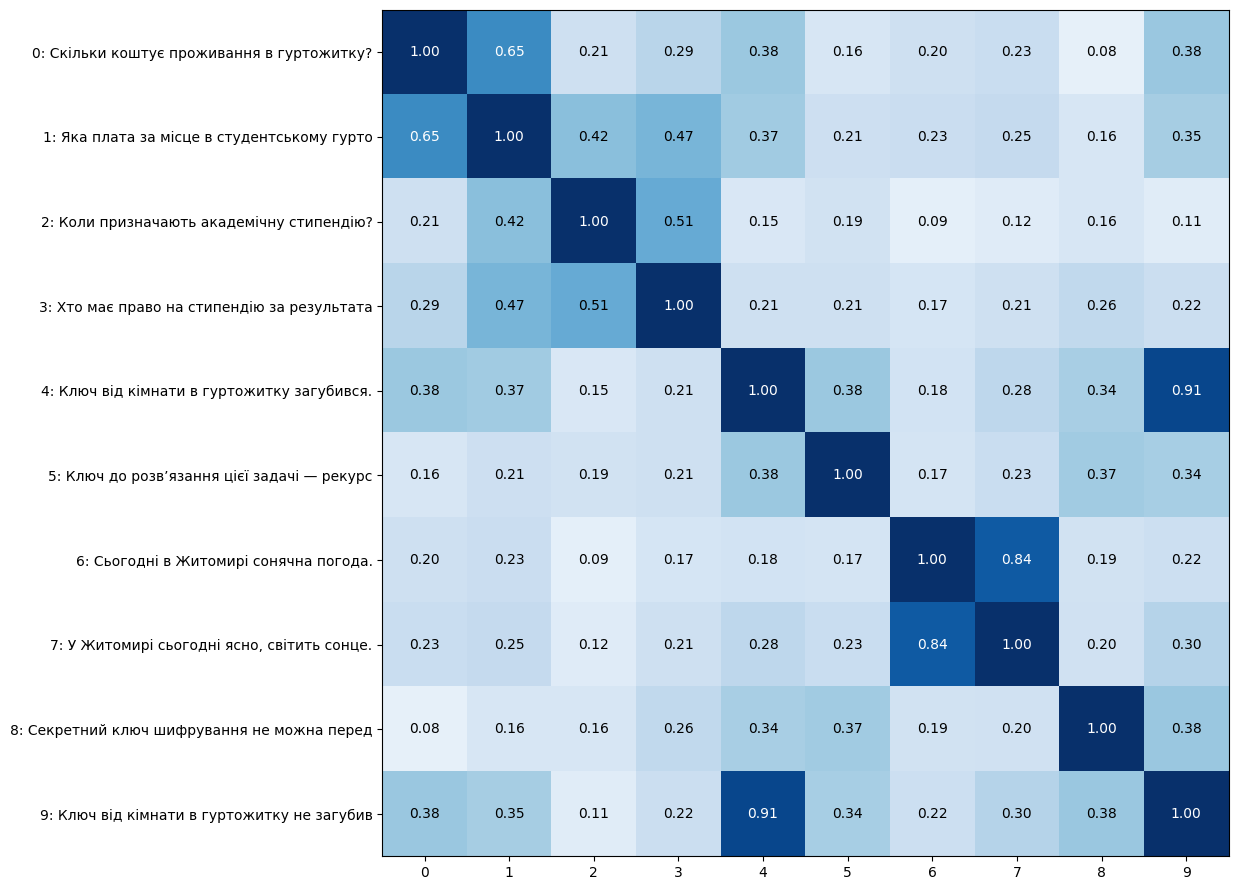

7 перефразування ↔ 6 оригінал                    0.837
9 заперечення ↔ 4 оригінал                       0.912
8 «ключ» (шифрування) ↔ 4 ключ від кімнати       0.341
8 «ключ» (шифрування) ↔ 5 ключ до задачі         0.367
для порівняння: 4 ↔ 5 (спільне слово «ключ»)     0.381

Найближчі до речення 7: 6 (0.84); 9 (0.30); 4 (0.28)
Найближчі до речення 8: 9 (0.38); 5 (0.37); 4 (0.34)
Найближчі до речення 9: 4 (0.91); 0 (0.38); 8 (0.38)


In [30]:
my_sentences = uni_sentences + [
    "У Житомирі сьогодні ясно, світить сонце.",                      # 7: перефразування речення 6
    "Секретний ключ шифрування не можна передавати стороннім.",     # 8: слово «ключ» в іншому значенні
    "Ключ від кімнати в гуртожитку не загубився.",                   # 9: заперечення речення 4
]
show_similarity_matrix(my_sentences, figsize=(12, 9))

E5 = model.encode(my_sentences, normalize_embeddings=True).astype(np.float32)
S5 = E5 @ E5.T
checks = [
    ("7 перефразування ↔ 6 оригінал", 7, 6),
    ("9 заперечення ↔ 4 оригінал", 9, 4),
    ("8 «ключ» (шифрування) ↔ 4 ключ від кімнати", 8, 4),
    ("8 «ключ» (шифрування) ↔ 5 ключ до задачі", 8, 5),
    ("для порівняння: 4 ↔ 5 (спільне слово «ключ»)", 4, 5),
]
for label, i, j in checks:
    print(f"{label:48s} {S5[i, j]:.3f}")
print()
for new_id in (7, 8, 9):
    order = [int(i) for i in np.argsort(-S5[new_id]) if i != new_id][:3]
    print(f"Найближчі до речення {new_id}: " + "; ".join(f"{i} ({S5[new_id, i]:.2f})" for i in order))

**Коментар до значень.**

- **Перефразування (7 ↔ 6): 0,837.** Речення мають лише спільне слово «Житомирі», а подібність висока: найближче до речення 7 є саме речення 6, наступні сусіди мають лише 0,30 і 0,28. Модель зіставляє зміст, а не слова.
- **Заперечення (9 ↔ 4): 0,912.** Це **більше**, ніж у перефразування. «Ключ… загубився» і «ключ… не загубився» модель вважає майже однаковими, бо вони про одне й те саме, а полярність («не») змінює вектор мало. Для RAG це важливий наслідок: ембединги вимірюють близькість теми, а не істинність, тож фрагмент із протилежним твердженням виглядатиме для пошуку так само релевантним.
- **Спільне слово, інший зміст (8 ↔ 4: 0,341; 8 ↔ 5: 0,367).** Подібність низька, навіть нижча, ніж між 4 і 5, які теж мають спільне слово «ключ» у різних значеннях (0,381). Найближчими до речення 8 усе ж виявились три речення зі словом «ключ» (9, 5, 4), проте з низькими значеннями 0,34–0,38: слово дає невеликий зсув, а значення ним не визначається.

### Питання 6. Яким чином модель Qwen/Qwen3-Embedding-0.6B саботує проведення dance-battle в «Житомирській політехніці»? Як думаєте, чи зможете Ви підібрати ембедингову модель, яка буде притримуватися іншої думки?

Модель ембедингів нічого не «вирішує»: вона відображає тексти у вектори за статистикою тих текстів, на яких тренувалась, а близькість двох фраз — це наслідок асоціацій, які вона там засвоїла. Тому «саботаж» тут — це те, що в просторі модель розташовує фразу про денс-батл відносно двох інших фраз («отримати гарну оцінку з СШІ» і «піти на перездачу»). Подивимось на числа, а потім спробуємо інші моделі.

In [31]:
dance_sentences = pseudo_random_sentences
E6 = model.encode(dance_sentences, normalize_embeddings=True).astype(np.float32)
S6 = E6 @ E6.T
print(f"денс-батл ↔ «{dance_sentences[1]}»: {S6[0, 1]:.3f}")
print(f"денс-батл ↔ «{dance_sentences[2]}»: {S6[0, 2]:.3f}")
print(f"гарна оцінка ↔ перездача: {S6[1, 2]:.3f}")
closest = 1 if S6[0, 1] > S6[0, 2] else 2
print(f"\nQwen3-Embedding: денс-батл найближчий до «{dance_sentences[closest]}»")

денс-батл ↔ «Отримати гарну оцінку з СШІ»: 0.395
денс-батл ↔ «Піти на перездачу»: 0.665
гарна оцінка ↔ перездача: 0.474

Qwen3-Embedding: денс-батл найближчий до «Піти на перездачу»


### Чи є ембедингова модель з іншою «думкою»

Перевіряємо кілька інших багатомовних моделей на тих самих трьох фразах: невелику `paraphrase-multilingual-MiniLM-L12-v2`, невелику `multilingual-e5-small` (їй для симетричних порівнянь потрібен префікс `query: `) і більшу `bge-m3`. Після кожної моделі звільняємо памʼять GPU.

In [32]:
import gc

OTHER_MODELS = [
    ("paraphrase-multilingual-MiniLM-L12-v2", "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", ""),
    ("multilingual-e5-small", "intfloat/multilingual-e5-small", "query: "),
    ("bge-m3", "BAAI/bge-m3", ""),
]
opinions = {"Qwen3-Embedding-0.6B": (float(S6[0, 1]), float(S6[0, 2]))}
for short_name, hf_name, prefix in OTHER_MODELS:
    try:
        other = SentenceTransformer(hf_name, device=device)
        vectors = other.encode([prefix + s for s in dance_sentences], normalize_embeddings=True).astype(np.float32)
        sims = vectors @ vectors.T
        opinions[short_name] = (float(sims[0, 1]), float(sims[0, 2]))
        del other
    except Exception as error:                                   # модель могла не завантажитись: не зупиняємо ноутбук
        print(f"{short_name}: не вдалося завантажити ({type(error).__name__}: {str(error)[:80]})")
    gc.collect()
    torch.cuda.empty_cache()

print(f"{'модель':40s} {'до «оцінка»':>12s} {'до «перездача»':>15s}   найближче до денс-батлу")
for name, (grade, retake) in opinions.items():
    print(f"{name:40s} {grade:12.3f} {retake:15.3f}   {'«гарна оцінка»' if grade > retake else '«перездача»'}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (33 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

модель                                    до «оцінка»  до «перездача»   найближче до денс-батлу
Qwen3-Embedding-0.6B                            0.395           0.665   «перездача»
paraphrase-multilingual-MiniLM-L12-v2           0.071           0.505   «перездача»
multilingual-e5-small                           0.847           0.892   «перездача»
bge-m3                                          0.342           0.418   «перездача»


**Висновок про «саботаж» і про альтернативні моделі.** Qwen3-Embedding розташовує фразу про денс-батл ближче до «Піти на перездачу» (0,665), ніж до «Отримати гарну оцінку з СШІ» (0,395), тобто за цим розташуванням денс-батл «веде» до перездачі. Це не позиція моделі, а наслідок статистики текстів, на яких вона навчалась. Ймовірне пояснення: «денс-батл» і «перездача» описують дії та події в студентському житті, а «гарна оцінка» є результатом; перевірити це за самими числами не можна.

Три інші моделі дали **таку саму відповідь**:

| модель | до «оцінка» | до «перездача» | ближче до денс-батлу |
|---|---|---|---|
| Qwen3-Embedding-0.6B | 0,395 | 0,665 | перездача |
| paraphrase-multilingual-MiniLM-L12-v2 | 0,071 | 0,505 | перездача |
| multilingual-e5-small | 0,847 | 0,892 | перездача |
| bge-m3 | 0,342 | 0,418 | перездача |

Тож підібрати модель з іншою «думкою» серед чотирьох перевірених не вдалося: усі однаково ставлять «перездачу» ближче. Розрив різний: у MiniLM великий (0,43), у bge-m3 і e5-small мінімальний (0,076 і 0,045). До того ж у e5-small усі значення високі (0,85–0,89): відомо, що моделі e5 дають стислу шкалу подібностей, тож абсолютні числа різних моделей порівнювати не можна. Це не доводить, що модель з протилежним порядком неможлива: перевірено лише три альтернативи на трьох фразах.

### Питання 7. У розділі 5 «Тексти на площині» ембединги проєктують на площину методом головних компонент (PCA). Чому речення однієї теми групуються разом, хоча проєкція втрачає більшу частину інформації? Чи можна за відстанню між точками на графіку судити про справжню подібність текстів?

PCA шукає напрямки, вздовж яких ембединги найбільше відрізняються один від одного (напрямки з найбільшою дисперсією). У цьому наборі найбільше джерело розбіжностей — **тема**: речення про гуртожиток схожі між собою й відрізняються від речень про стипендію чи борщ. Тому перші дві компоненти ловлять саме цю грубу структуру, а те, що відкидається (дрібніші відмінності всередині теми, стиль, довжина), лежить у решті 1022 вимірів і на групування тем майже не впливає.

Судити про справжню подібність за відстанню на графіку **не можна**. Проєкція ортогональна, тому вона може лише стискати відстані; дві точки можуть опинитися поруч на площині, бо їхні відмінності припадають на відкинуті напрямки. Відстань на графіку — це лише нижня оцінка відстані у повному просторі. Код нижче показує, яку частку дисперсії зберігають дві компоненти, наскільки відстані на площині корелюють зі справжніми і яку пару речень проєкція «зблизила» найсильніше. Цікаві кількісні висновки про справжню подібність дає косинус у повному 1024-вимірному просторі.

In [33]:
pca_texts = [t for group in topics.values() for t in group]       # змінна texts вище перезаписана в розділі 9, тому будуємо список наново
pca_points = model.encode(pca_texts, normalize_embeddings=True).astype(np.float32)
pca_centered = pca_points - pca_points.mean(axis=0)
_, singular_values, components = np.linalg.svd(pca_centered, full_matrices=False)
explained = singular_values ** 2 / np.sum(singular_values ** 2)
print(f"Частка дисперсії: PC1 {explained[0]:.1%}, PC2 {explained[1]:.1%}, разом {explained[:2].sum():.1%} (втрачено {1 - explained[:2].sum():.1%})")

flat = pca_centered @ components[:2].T


def pairwise_distances(X):
    return np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1)


full_d, flat_d = pairwise_distances(pca_points), pairwise_distances(flat)
iu = np.triu_indices(len(pca_texts), k=1)
print(f"Кореляція відстаней на площині та у повному просторі: {np.corrcoef(full_d[iu], flat_d[iu])[0, 1]:.2f}")
print("Проєкція ніколи не збільшує відстані:", bool(np.all(flat_d <= full_d + 1e-4)))

topic_of = np.array(labels)
cos_all = pca_points @ pca_points.T
same = topic_of[:, None] == topic_of[None, :]
off_diagonal = ~np.eye(len(pca_texts), dtype=bool)
print(f"Середній косинус у межах теми: {cos_all[same & off_diagonal].mean():.2f}; між різними темами: {cos_all[~same].mean():.2f}")

# Пара, яка на площині близька, а у повному просторі далека
far_in_full = full_d[iu] > np.median(full_d[iu])
candidates = [(flat_d[i, j], full_d[i, j], i, j) for (i, j), far in zip(zip(*iu), far_in_full) if far]
flat_value, full_value, i, j = min(candidates)
print(f"\nПара, яка на площині майже збігається (відстань {flat_value:.2f}), а у повному просторі далека ({full_value:.2f}, косинус {cos_all[i, j]:.2f}):")
print(f"  «{pca_texts[i]}» [{labels[i]}]\n  «{pca_texts[j]}» [{labels[j]}]")

Частка дисперсії: PC1 14.1%, PC2 13.3%, разом 27.4% (втрачено 72.6%)
Кореляція відстаней на площині та у повному просторі: 0.51
Проєкція ніколи не збільшує відстані: True
Середній косинус у межах теми: 0.40; між різними темами: 0.22

Пара, яка на площині майже збігається (відстань 0.10), а у повному просторі далека (1.24, косинус 0.23):
  «Як перескласти екзамен?» [оцінювання]
  «Найкращий фільм 2024 року.» [інше]


**Коментар до чисел.** Дві компоненти зберігають лише **27,4 %** дисперсії (PC1 14,1 %, PC2 13,3 %), тобто 72,6 % інформації втрачено, тому проєкція груба: кореляція відстаней на площині та у повному просторі лише **0,51**. Групування за темами все ж проявляється, бо різниця між темами є в повному просторі: середній косинус у межах однієї теми **0,40**, а між різними **0,22**, і PCA вловлює частину цієї різниці.

Перевірка підтвердила, що проєкція «ніколи не збільшує відстані» (`True`), тож відстань на графіку може лише занижувати справжню. Приклад із даних: «Як перескласти екзамен?» (тема «оцінювання») і «Найкращий фільм 2024 року.» (тема «інше») на площині майже збігаються (відстань 0,10), хоча у повному просторі вони далекі (відстань 1,24, косинус 0,23). Тому судити про подібність за графіком не можна: близькість точок лише необхідна умова, а не доказ подібності.

### Питання 8. Порівняйте дві матриці подібності в розділі 6 «Запит і документ кодуються по-різному». Що змінює інструкція, яку модель додає до запиту?

Інструкція дописується лише до **запитів** (промпт `query`), а документи кодуються без неї. Вона повідомляє моделі, яку задачу розвʼязує пошук («за пошуковим запитом знайти фрагменти, що містять відповідь»), і тому вектор запиту зсувається в ту область простору, де лежать фрагменти-відповіді, а не просто схожі за словами короткі питання. Матриці відрізняються значеннями подібності; важливо дивитися не на їхній абсолютний рівень, а на **запас** між правильним фрагментом (діагональ) і найближчим хибним. Порівнюємо чотири запити й чотири фрагменти обома способами за метриками, які однозначно відповідають на це питання.

In [34]:
import pandas as pd

print("Промпт запиту:", repr(model.prompts["query"]))
passage_matrix = model.encode(passages, normalize_embeddings=True).astype(np.float32)
rows = []
for prompt_name in [None, "query"]:
    query_matrix = model.encode(queries, normalize_embeddings=True, prompt_name=prompt_name).astype(np.float32)
    sim = query_matrix @ passage_matrix.T
    diagonal = np.diag(sim)
    wrong = np.where(np.eye(len(sim), dtype=bool), -np.inf, sim)
    rows.append({
        "промпт запиту": prompt_name or "без промпта",
        "середнє на діагоналі": diagonal.mean(),
        "середнє поза діагоналлю": sim[~np.eye(len(sim), dtype=bool)].mean(),
        "запас: діагональ − найкращий хибний": (diagonal - wrong.max(axis=1)).mean(),
        "правильних у топ-1": int((sim.argmax(axis=1) == np.arange(len(sim))).sum()),
    })
    print(f"\nМатриця подібності (промпт: {prompt_name}):")
    print(np.round(sim, 2))
pd.DataFrame(rows).round(3)

Промпт запиту: 'Instruct: Given a web search query, retrieve relevant passages that answer the query\nQuery:'

Матриця подібності (промпт: None):
[[0.44 0.52 0.28 0.15]
 [0.17 0.69 0.22 0.15]
 [0.15 0.11 0.43 0.15]
 [0.2  0.16 0.16 0.38]]

Матриця подібності (промпт: query):
[[0.51 0.61 0.33 0.18]
 [0.21 0.76 0.24 0.15]
 [0.2  0.14 0.45 0.17]
 [0.19 0.17 0.17 0.4 ]]


,промпт запиту,середнє на діагоналі,середнє поза діагоналлю,запас: діагональ − найкращий хибний,правильних у топ-1
0,без промпта,0.485,0.202,0.211,3
1,query,0.530,0.230,0.218,3


**Висновок за числами.** Інструкція підвищує всі значення подібності: середнє на діагоналі зростає з 0,485 до 0,530, а поза діагоналлю з 0,202 до 0,230. Тобто це в основному зсув усієї шкали. Запас між правильним фрагментом і найкращим хибним майже не змінився: **0,211 → 0,218**, а кількість правильних відповідей у топ-1 лишилась **3 із 4** в обох випадках.

На цих чотирьох парах інструкція не покращує ранжування. Єдина помилка однакова в обох матрицях: питання «До якої дати платити за гуртожиток?» знаходить фрагмент про тишу (0,52 без інструкції, 0,61 з нею) замість фрагмента про оплату (0,44 і 0,51). Це та сама проблема, яку розв'язує розділ 9. Вибірка з чотирьох питань замала, щоб робити висновки про користь інструкції загалом; відомо лише, що тут вона переносить усі значення вгору.

### Питання 9. Поставте в розділі 8 «Пошук вручну» три власні питання до документів університету. Чи потрапив правильний документ до трьох найближчих фрагментів? Порівняйте подібність найкращого фрагмента з подібністю для питання, на яке в документах немає відповіді.

In [35]:
OWN_QUESTIONS = [
    ("Які обовʼязки має староста академічної групи?", "336"),
    ("Які бувають види практики студентів?", "291"),
    ("Які санкції застосовують за академічний плагіат?", "1199"),
]
NO_ANSWER = [
    "Скільки коштує обід у студентській їдальні?",            # питання з демо
    "Яка вартість квитка на автобус до Києва?",               # власне питання без відповіді
]

best_scores = {}
for question, gold_doc in OWN_QUESTIONS:
    if gold_doc not in documents:
        print(f"Питання: {question} — документ {gold_doc} не завантажено (скан без тексту), пропускаємо\n")
        continue
    top = search(question, chunk_embeddings, k=3)
    docs_in_top = [chunks[i]["doc_id"] for i, _ in top]
    best_scores[question] = top[0][1]
    print(f"Питання: {question}  (очікуємо документ {gold_doc})")
    print(f"  правильний документ у топ-3: {'так' if gold_doc in docs_in_top else 'ні'}; найкращий фрагмент із документа {docs_in_top[0]}")
    for i, score in top:
        print(f"    {score:.3f}  [{chunks[i]['doc_id']}] {chunks[i]['text'][:230]}…")
    print()

print("Питання без відповіді в документах:")
for question in NO_ANSWER:
    i, score = search(question, chunk_embeddings, k=1)[0]
    best_scores[question] = score
    print(f"  {score:.3f}  {question}  → найближчий фрагмент із документа {chunks[i]['doc_id']}: {chunks[i]['text'][:120]}…")

with_answer = [best_scores[question] for question, _ in OWN_QUESTIONS if question in best_scores]
without_answer = [best_scores[question] for question in NO_ANSWER]
print(f"\nНайкраща подібність, питання з відповіддю: {min(with_answer):.3f}…{max(with_answer):.3f}; без відповіді: {min(without_answer):.3f}…{max(without_answer):.3f}")

Питання: Які обовʼязки має староста академічної групи?  (очікуємо документ 336)
  правильний документ у топ-3: так; найкращий фрагмент із документа 336
    0.817  [336] ЗМІСТ 1. Загальні положення…………………………………………………………………….. 3 2. Обов’язки старости...…………………………………………………………………... 3 3. Права старости………………………………………………………………………..... 3 4. Відповідальність старости………………………………………………………...…… 4 5. Показ…
    0.731  [336] сь період навчання. Звільнення від виконання обов’язків старости може здійснюватись за власним бажанням, з ініціативи адміністрації університету, факультету або студентів даної групи, якщо староста не справляється зі своїми обов’я…
    0.726  [336]  ректоратом або за їх дорученням. У своїй роботі староста академічної групи співпрацює з куратором та ментором групи. 1.3. У виборах старости студентської академічної групи беруть участь всі студенти відповідної академічної групи.…

Питання: Які бувають види практики студентів?  (очікуємо документ 291)
  правильний документ у топ-3

**Результат і висновок.** Для всіх трьох власних питань правильний документ потрапив у топ-3, і навіть найкращий фрагмент був із потрібного документа. Найкраща подібність: староста — 0,817, плагіат — 0,714, види практики — 0,551.

Питання без відповіді дали 0,514 («обід у студентській їдальні»; найближчий фрагмент про оплату гуртожитку) і 0,337 («квиток на автобус до Києва»; фрагмент про стипендійний фонд). Діапазони не перетинаються (питання з відповіддю: 0,551…0,817; без відповіді: 0,337…0,514), але розрив між ними всього 0,037, а питання про практику (0,551) лише трохи вище за питання про їдальню (0,514). Пошук **завжди** повертає «найближчий» фрагмент, навіть коли відповіді немає, а поріг подібності на п'яти прикладах був би ненадійним. Є й побічне спостереження: найкращим фрагментом для питання про обов'язки старости став зміст документа (рядок «2. Обов'язки старости…»), а не сам розділ з обов'язками: зміст збігається зі словами питання, але відповіді не містить.

### Питання 10. Чому дописування назви документа на початок фрагмента (розділ 9) покращує пошук? Знайдіть приклад фрагмента, який без назви документа втрачає зміст.

Фрагмент, вирваний із документа, не знає, про що весь документ. Речення «Студент вносить авансовий платіж за 1 семестр до 1 вересня» не містить слова «гуртожиток», хоча саме про гуртожиток воно й написане; зміст береться з назви положення, у якому воно стоїть. Назва на початку фрагмента повертає цю інформацію в текст, який кодується: ембединг фрагмента тепер відображає не лише власні слова, а й тему документа, і питання «До якої дати платити за гуртожиток?» знаходить його легше. Платимо за це кількома токенами на фрагмент.

Нижче перевіряємо це на 9 питаннях бенчмарку з розділу 8 і на власних питаннях: рахуємо, на якій позиції стоїть перший фрагмент потрібного документа без назви й з нею, і показуємо фрагмент, якому назва допомогла найбільше.

In [36]:
def first_gold_rank(embeddings, question, gold_doc):
    """Позиція (з 1) першого фрагмента з потрібного документа серед усіх фрагментів, відсортованих за подібністю."""
    query_vector = model.encode(question, normalize_embeddings=True, prompt_name="query").astype(np.float32)
    order = np.argsort(-(embeddings.astype(np.float32) @ query_vector))
    for rank, i in enumerate(order, start=1):
        if chunks[int(i)]["doc_id"] == gold_doc:
            return rank, int(i)
    return None, None


import pandas as pd

rows = []
for question, gold_doc in QUESTIONS + OWN_QUESTIONS:
    if gold_doc not in documents:
        continue
    rank_plain, id_plain = first_gold_rank(chunk_embeddings, question, gold_doc)
    rank_titled, id_titled = first_gold_rank(titled_embeddings, question, gold_doc)
    rows.append({"питання": question[:58], "документ": gold_doc, "без назви": rank_plain, "з назвою": rank_titled, "виграш": rank_plain - rank_titled, "фрагмент": id_titled})
table = pd.DataFrame(rows)
display(table.drop(columns="фрагмент"))
print(f"Позиція краща з назвою: {(table['виграш'] > 0).sum()} питань; гірша: {(table['виграш'] < 0).sum()}; однакова: {(table['виграш'] == 0).sum()}")

best = table.sort_values("виграш", ascending=False).iloc[0]
fragment = chunks[int(best["фрагмент"])]
print(f"\nНайбільший виграш: «{best['питання']}» — позиція {best['без назви']} → {best['з назвою']}")
print(f"Фрагмент ({fragment['doc_id']}, {documents[fragment['doc_id']]['title']}):\n{fragment['text'][:500]}…")
subject_words = ["гуртожит", "стипенд", "староста", "омбудсман", "практик", "доброчесн", "оцінюван"]
print("Чи згадує сам текст фрагмента тему документа:", [w for w in subject_words if w in fragment["text"].lower()] or "жодного з ключових слів тем")

,питання,документ,без назви,з назвою,виграш
0,До якої дати потрібно оплатити гуртожиток за п...,348,1,1,0
1,Чи можна платити за гуртожиток щомісяця?,348,1,1,0
2,Чи можна жити в гуртожитку з дружиною?,348,2,1,1
3,З якої години в гуртожитку має бути тиша?,1219,1,1,0
4,Коли обирають старосту на першому курсі?,336,1,1,0
5,Скільки балів потрібно для оцінки «добре» B?,275,3,2,1
6,"Що робити, якщо я не згоден з оцінкою за семестр?",275,2,1,1
7,Яку частку кредитів становлять вибіркові дисци...,277,1,1,0
8,Хто такий студентський омбудсман?,4389,1,1,0
9,Які обовʼязки має староста академічної групи?,336,1,1,0


Позиція краща з назвою: 3 питань; гірша: 0; однакова: 9

Найбільший виграш: «Чи можна жити в гуртожитку з дружиною?» — позиція 2 → 1
Фрагмент (348, Положення про користування гуртожитками):
 місця проживання за місцем розташування закладу освіти. 2.2. У гуртожитках Житомирської політехніки можуть проживати: 1) здобувачі освіти за заочною формою здобуття освіти за потреби виконання компонентів навчального плану, що передбачають особисту присутність здобувача освіти в Житомирській політехніці; 2) здобувачі вищої освіти, які здобувають освіту за денною, заочною формою в іншому закладі освіти, що не має місць (або їх недостатньо) для проживання здобувачів освіти у власних гуртожитках; …
Чи згадує сам текст фрагмента тему документа: ['гуртожит']


**Приклад і коментар.** Найкращий приклад — фрагмент «Студент вносить авансовий платіж за 1 семестр до 1 вересня…», у якому немає слова «гуртожиток». Без назви положення він отримує для питання «До якої дати платити за гуртожиток?» лише **0,51** і програє фрагменту про тишу (**0,61**). З назвою «Положення про користування гуртожитками» подібність зростає до **0,76**, а фрагмент про тишу залишається на 0,59, тож правильний фрагмент випереджає.

На 12 питаннях (9 з бенчмарку й 3 власні) назва покращила позицію першого фрагмента з потрібного документа у **3 випадках** (наприклад, «Чи можна жити в гуртожитку з дружиною?» з 2-ї позиції на 1-шу, «Скільки балів потрібно для оцінки “добре” B?» з 3-ї на 2-гу), не погіршила в жодному, а в 9 випадках потрібний документ і без назви вже стояв першим. Отже ефект реальний, але на цьому наборі невеликий: більшість питань і без назви знаходили потрібний документ. Зауважте, що для фрагмента з найбільшим виграшем (пункт 2.2 про те, хто може проживати) слово «гуртожит» у тексті все ж є: назва допомагає не лише тоді, коли тема повністю відсутня у фрагменті.